# FeatherLM demo

FeatherLM is a copy editor for AI-drafted marketing copy (landing pages, launch emails, LinkedIn posts). It rewrites the text so it reads like a skilled human wrote it and keeps every fact: no number, name or claim is added, dropped or changed. It runs an open model on Fireworks (GLM-5.3 Flash) inside a verify-and-revise harness: write a rewrite, check it with four gates (`hackathon/harness/gates.py`: G1 nothing invented, G2 nothing lost, G3 no AI tells, G4 not gutted), send the failed gates back as targeted fixes, keep the best version. Frontier models with a good prompt remove the AI tells but often drop or change a fact; the harness is there to catch that.

This notebook runs offline in a few seconds. Every number below is read at runtime from committed files (`evals/`, `hackathon/report/results.json`). The last cell can call Fireworks live; it is off by default (`RUN_LIVE = False`).

In [1]:
import html, json, re, sys, time
from pathlib import Path
from IPython.display import HTML, Image, Markdown, display

RUN_LIVE = False   # True = also rewrite one draft live on Fireworks (needs FIREWORKS_API_KEY in ~/.config/humanlm/keys.env)
T0 = time.time()

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "evals/eval_all.jsonl").exists())
sys.path[:0] = [str(ROOT / d) for d in ("pipeline", "hackathon/harness", "hackathon/eval", "hackathon/audit")]
import gates                  # the one G1-G4 definition (shared by the harness and the scorer)
import score_all as sa        # must-keep check and the number formats used in RESULTS.md
import audit as au            # lenient G1/G2 (forgives numerals spelled out and similar artefacts)

def jsonl(rel):
    return [json.loads(l) for l in open(ROOT / rel, encoding="utf-8") if l.strip()]

CLAUDE_RUN = "evals/runs/hack_strong_claude-opus-5-5.jsonl"
FEATHER_RUN = "evals/runs/hack_O3c_glm_prompt_harness_style.jsonl"
items = {r["id"]: r for r in jsonl("evals/eval_all.jsonl")}
extra = {r["id"]: r for f in ("evals/dev_set.jsonl", "evals/trick_set.jsonl") for r in jsonl(f)}   # must_keep lives here
claude = {r["id"]: r for r in jsonl(CLAUDE_RUN)}
feather = {r["id"]: r for r in jsonl(FEATHER_RUN)}
print(f"{len(items)} eval items; {len(claude)} Claude rows ({next(iter(claude.values()))['system']}); "
      f"{len(feather)} FeatherLM rows ({next(iter(feather.values()))['system']})")

130 eval items; 130 Claude rows (frontier-strong:claude-opus-5-5); 130 FeatherLM rows (O3c_glm_prompt_harness_style)


## 1. One draft, two rewrites

Pick the item deterministically: `dev-060` if it qualifies, otherwise the first id in `eval_all.jsonl` that does. An item qualifies when FeatherLM passes all four gates and Claude Opus 5.5 (strong prompt) fails G1 or G2, **and** Claude still fails G1 or G2 under the lenient audit check, so the example is a real fact problem and not a gate artefact (a numeral spelled out, a speech-verb match).

In [2]:
DEFAULT_ID = "dev-060"

def why(i):
    d, c, f = items[i]["ai_draft"], claude[i]["output"], feather[i]["output"]
    gf, gc, lc = gates.check(d, f), gates.check(d, c), au.gate_check(d, c)
    strict = not (gc["g1_nothing_invented"] and gc["g2_nothing_lost"])
    lenient = not (lc["G1_lenient"] and lc["G2_lenient"])
    return gf["pass"] and strict and lenient, gf, gc, lc

order = [DEFAULT_ID] + [i for i in items if i != DEFAULT_ID]
for i in order:
    ok, gf, gc, lc = why(i)
    if ok:
        ITEM = i
        break
    if i == DEFAULT_ID:
        added = sorted(set(w.lower() for w in gates.m.ATTRIB.findall(claude[i]["output"]))
                       - set(w.lower() for w in gates.m.ATTRIB.findall(items[i]["ai_draft"])))
        print(f"{i} skipped: FeatherLM pass={gf['pass']}; Claude strict G1={gc['g1_nothing_invented']} G2={gc['g2_nothing_lost']}, "
              f"lenient G1={lc['G1_lenient']} G2={lc['G2_lenient']}. Claude's strict problems: {gc['problems']}"
              + (f" (speech verbs matched: {added})" if added else ""))

ok, gf, gc, lc = why(ITEM)
print(f"Chosen: {ITEM}. FeatherLM passes all gates; Claude fails strict "
      + ", ".join(g for g, k in (("G1", "g1_nothing_invented"), ("G2", "g2_nothing_lost")) if not gc[k])
      + " and lenient " + ", ".join(g for g in ("G1", "G2") if not lc[g + "_lenient"])
      + f". Lenient reasons: {[k for k, v in lc['reasons'].items() if v]}")

dev-060 skipped: FeatherLM pass=True; Claude strict G1=False G2=True, lenient G1=True G2=True. Claude's strict problems: ["You added a quote or a 'says/said' attribution that is not in the draft. Remove it."] (speech verbs matched: ['added', 'recalled'])
Chosen: dev-016. FeatherLM passes all gates; Claude fails strict G2 and lenient G2. Lenient reasons: ['g2_numbers_dropped_real', 'g2_names_dropped_artefact']


In [3]:
facts = extra.get(ITEM, {}).get("must_keep", [])
NUM, CAP = sa.NUM, sa.CAP

def marked(text, facts):
    """Escape the text and highlight the numbers/names of each must-keep fact that the text keeps."""
    t = html.escape(text)
    toks = sorted({h for f in facts if sa.kept(f, text) for h in NUM.findall(f) + CAP.findall(f)}, key=len, reverse=True)
    if toks:
        t = re.sub("|".join(r"(?<![\w])" + re.escape(html.escape(x)) + r"(?![\w])" for x in toks),
                   lambda mt: f"<mark style='background:#c8f7c5'>{mt.group(0)}</mark>", t, flags=re.I)
    return t.replace("\n", "<br>")

def checklist(text, facts):
    return "".join(f"<div style='color:{'#137333' if sa.kept(f, text) else '#c5221f'}'>"
                   f"{'&#10003;' if sa.kept(f, text) else '&#10007; missing:'} {html.escape(f)}</div>" for f in facts)

def gate_box(draft, out):
    g = gates.check(draft, out)
    badges = " ".join(f"<b style='color:{'#137333' if g[k] else '#c5221f'}'>{n}</b>" for n, k in
                      (("G1", "g1_nothing_invented"), ("G2", "g2_nothing_lost"), ("G3", "g3_no_ai_tells"), ("G4", "g4_not_gutted")))
    probs = "".join(f"<li>{html.escape(p)}</li>" for p in g["problems"]) or "<li>none</li>"
    return f"{badges} &nbsp; length {g['len_ratio']}x<br>gates.check() problems:<ul style='margin:2px 0'>{probs}</ul>"

draft = items[ITEM]["ai_draft"]
cols = [("AI draft (input)", draft, "<i>source text</i>"),
        (f"Claude Opus 5.5, strong prompt<br><code>{claude[ITEM]['system']}</code>", claude[ITEM]["output"], gate_box(draft, claude[ITEM]["output"])),
        (f"FeatherLM (GLM-5.3 Flash + harness)<br><code>{feather[ITEM]['system']}</code>", feather[ITEM]["output"], gate_box(draft, feather[ITEM]["output"]))]
td = "style='vertical-align:top;text-align:left;border:1px solid #ccc;padding:8px;width:33%'"
display(HTML(f"<p><b>{ITEM}</b>, must-keep facts from the eval set: {len(facts)}</p><table style='border-collapse:collapse;font-size:13px'>"
             + "<tr>" + "".join(f"<th {td}>{h}</th>" for h, _, _ in cols) + "</tr>"
             + "<tr>" + "".join(f"<td {td}>{marked(t, facts)}</td>" for _, t, _ in cols) + "</tr>"
             + "<tr>" + "".join(f"<td {td}>{checklist(t, facts)}</td>" for _, t, _ in cols) + "</tr>"
             + "<tr>" + "".join(f"<td {td}>{g}</td>" for _, _, g in cols) + "</tr></table>"
             + "<p style='font-size:12px'>Must-keep check is the scorer's crude one (<code>score_all.kept</code>): every number and "
               "capitalised name in the fact must appear, else 60% of its content words.</p>"))

AI draft (input),"Claude Opus 5.5, strong promptfrontier-strong:claude-opus-5-5",FeatherLM (GLM-5.3 Flash + harness)O3c_glm_prompt_harness_style
"Simple, Transparent Pricing That Grows With YouAt Stackhand, we believe world-class monitoring should be accessible to everyone. That's why we offer flexible plans designed to scale seamlessly alongside your business.🆓 Free — Perfect for getting started. Monitor up to 3 endpoints with lightning-fast 1-minute checks.🚀 Team — Just $29/month for 50 monitors, with the same 1-minute checks.No hidden fees. No surprises. Just peace of mind.Start free today!","Pricing That Grows With YouStackhand plans scale as your business grows, so you can start small and add monitors when you need them.Free: Monitor up to 3 endpoints with checks every minute.Team: $29/month for 50 monitors, also checked every minute.There are no hidden fees.Start free today.","Pricing That Grows With YouAt Stackhand, we think good monitoring should be available to everyone, so we offer flexible plans that scale alongside your business.Free: perfect for getting started. You can monitor up to 3 endpoints with 1-minute checks.Team: just $29/month for 50 monitors, also with 1-minute checks.No hidden fees and no surprises. Start free today."
✓ Free: 3 monitors✓ Team: $29/month for 50 monitors✓ 1-minute checks on both plans✓ Start free,✓ Free: 3 monitors✓ Team: $29/month for 50 monitors✗ missing: 1-minute checks on both plans✓ Start free,✓ Free: 3 monitors✓ Team: $29/month for 50 monitors✓ 1-minute checks on both plans✓ Start free
source text,"G1 G2 G3 G4 length 0.712xgates.check() problems:You dropped these numbers from the draft: 1. Put each back exactly.You dropped these names: just, perfect. Put them back.",G1 G2 G3 G4 length 0.863xgates.check() problems:none


## 2. Leaderboard (all 250 items: eval 130 + held-out 120)

In [4]:
res = json.load(open(ROOT / "hackathon/report/results.json", encoding="utf-8"))
meta = {s["label"]: s for s in res["systems"]}
blk = res["blocks"]["all"]
th = "style='border:1px solid #ccc;padding:4px 8px;text-align:left'"
rows = []
for e in blk["systems"]:
    s = meta[e["label"]]
    cost = f"${s['cost_per_1k_usd']:.2f}" if s.get("cost_per_1k_usd") is not None else "n/a"
    lat = f"{s['latency_ms']['p50']/1000:.1f}s" if s.get("latency_ms") else "n/a"
    bold = e["label"] in (res["reference"], feather[ITEM]["system"])
    cells_ = [e["label"] + (f" ({e['n']} items)" if e["missing"] else ""), sa.pct(e["summary"]["pass"]),
              sa.pct(e["summary"]["pass_lenient"]), sa.delta(e), cost, lat]
    rows.append("<tr>" + "".join(f"<td {th}>{'<b>' + html.escape(c) + '</b>' if bold else html.escape(c)}</td>" for c in cells_) + "</tr>")
hdr = ["System", "Fact-safe rate, strict [95% CI]", "Fact-safe rate, lenient", f"Δ strict vs {res['reference']}", "$ / 1k rewrites", "p50 latency"]
display(HTML(f"<p>{blk['n_items']} items, reference <code>{res['reference']}</code>, Δ by paired bootstrap. Source: hackathon/report/results.json</p>"
             f"<table style='border-collapse:collapse;font-size:13px'><tr>{''.join(f'<th {th}>{h}</th>' for h in hdr)}</tr>{''.join(rows)}</table>"))

lines = ["**Pairwise LLM judge** (both orders; A wins / B wins / ties, two-sided sign test):", ""]
for j in res["judges"]:
    line = f"- `{j['a']}` vs `{j['b']}` ({j['model'].split('/')[-1]}): overall {j['win']}/{j['loss']}/{j['tie']} (p={j['sign_test_p']:.3f})"
    if isinstance(j.get("style"), dict) and "sign_test_p" in j["style"]:
        line += f", style {j['style']['win']}/{j['style']['loss']}/{j['style']['tie']} (p={j['style']['sign_test_p']:.3f})"
    lines.append(line)
display(Markdown("\n".join(lines)))

System,"Fact-safe rate, strict [95% CI]","Fact-safe rate, lenient",Δ strict vs frontier-strong:claude-opus-5-5,$ / 1k rewrites,p50 latency
O3j_glm_bestof3_judged (120 items),"98% [93, 99]","99% [95, 100]","+23 pp [+16, +32], significant (p=0.000)",$2.55,12.6s
O3c_glm_prompt_harness_style,"97% [94, 99]","98% [95, 99]","+25 pp [+20, +31], significant (p=0.000)",$0.81,3.3s
O3e_glm_harness_cliche,"96% [93, 98]","99% [97, 100]","+25 pp [+19, +30], significant (p=0.000)",$0.81,3.0s
O3d_glm_harness_anticopy,"95% [92, 97]","98% [95, 99]","+24 pp [+18, +30], significant (p=0.000)",$0.85,2.9s
O3b_glm_prompt_harness,"94% [91, 97]","97% [94, 99]","+23 pp [+18, +28], significant (p=0.000)",$0.55,1.6s
F1H_opus_harness,"94% [90, 96]","97% [94, 99]","+22 pp [+17, +28], significant (p=0.000)",$15.83,4.8s
O3_glm_harness,"93% [89, 96]","97% [94, 99]","+21 pp [+16, +27], significant (p=0.000)",$0.28,2.6s
O2_glm_prompt,"73% [67, 79]","80% [74, 84]","+2 pp [-5, +8], n.s. (p=0.620)",$0.31,1.2s
frontier-strong:claude-opus-5-5,"72% [66, 77]","85% [80, 89]",reference,$9.15,3.8s
F1h_opus_humanizer,"60% [54, 66]","77% [71, 82]","-12 pp [-17, -6], significant (p=0.000)",$50.26,3.7s


**Pairwise LLM judge** (both orders; A wins / B wins / ties, two-sided sign test):

- `hack_O3_glm_harness_heldout.jsonl` vs `hack_F1H_opus_heldout.jsonl` (kimi-k3): overall 52/31/37 (p=0.028), style 41/17/62 (p=0.002)
- `hack_O3_glm_harness_heldout.jsonl` vs `hack_strong_claude-opus-5-5_heldout.jsonl` (kimi-k3): overall 42/35/41 (p=0.494), style 28/30/60 (p=0.896)
- `hack_O3_glm_harness.jsonl` vs `hack_F1H_opus.jsonl` (kimi-k3): overall 40/47/43 (p=0.520), style 32/46/52 (p=0.141)
- `hack_O3_glm_harness.jsonl` vs `hack_F2_gpt61_terra.jsonl` (kimi-k3): overall 35/46/49 (p=0.266), style 32/38/60 (p=0.550)
- `hack_O3_glm_harness.jsonl` vs `hack_strong_claude-opus-5-5.jsonl` (kimi-k3): overall 34/57/39 (p=0.021), style 25/56/49 (p=0.001)
- `hack_O3b_glm_prompt_harness.jsonl` vs `hack_strong_claude-opus-5-5.jsonl` (kimi-k3): overall 35/60/35 (p=0.013), style 26/60/44 (p=0.000)
- `hack_O3c_glm_prompt_harness_style.jsonl` vs `hack_strong_claude-opus-5-5.jsonl` (kimi-k3): overall 35/52/43 (p=0.086), style 33/46/51 (p=0.177)

## 3. Chart

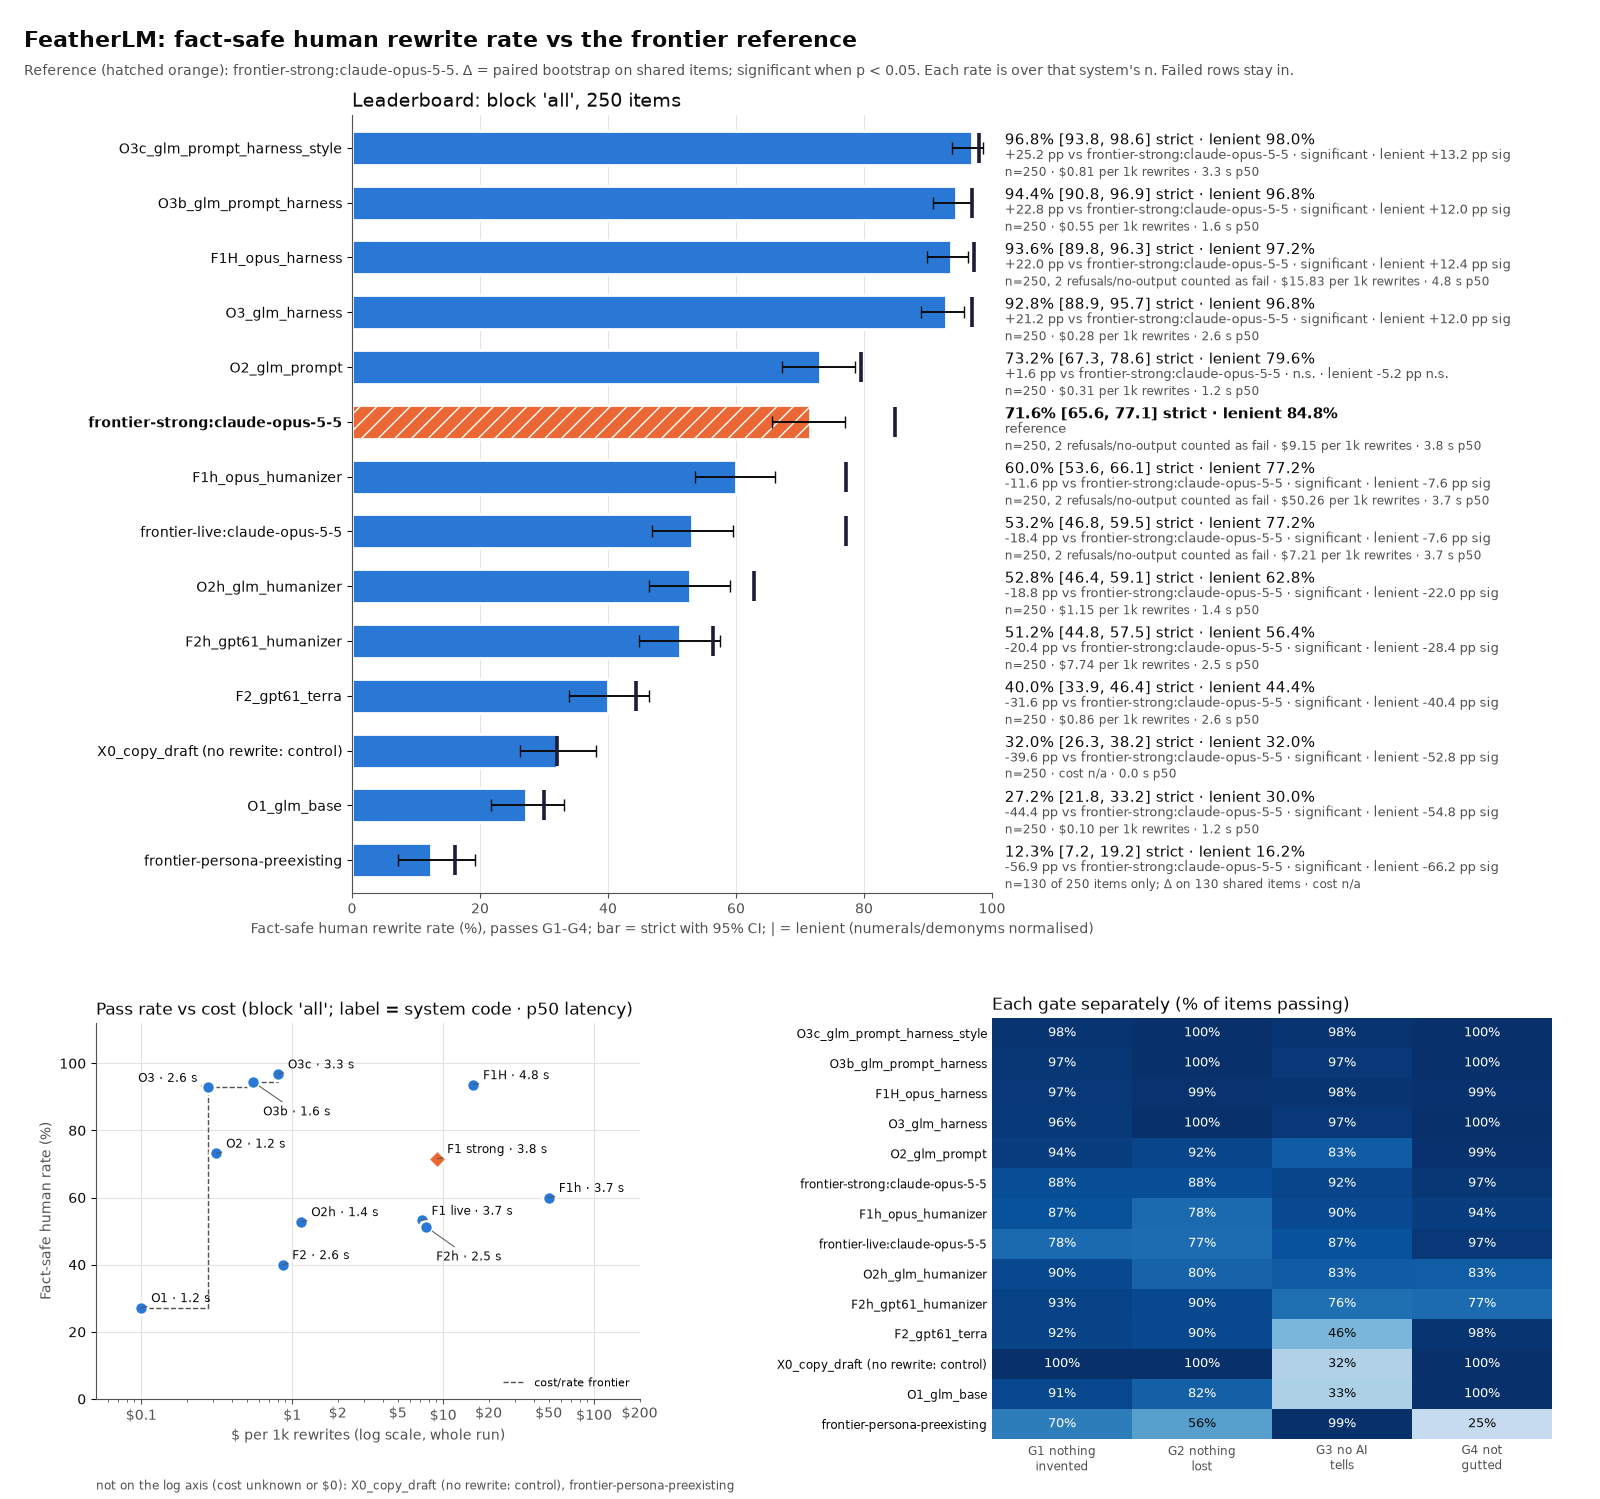

Offline part done in 1.5s


In [5]:
display(Image(filename=str(ROOT / "hackathon/report/leaderboard.png"), width=900))
print(f"Offline part done in {time.time() - T0:.1f}s")

## 4. Live (optional)

Set `RUN_LIVE = True` in the first code cell to rewrite the chosen draft live with the same settings as the FeatherLM row (read from its manifest `hackathon/runs/O3c_glm_prompt_harness_style.json`). It calls `harness.rewrite()` in-process, so no run file or manifest is written. The key is read from `~/.config/humanlm/keys.env` and never printed; `truststore` makes HTTPS use the OS certificate store (needed behind a TLS-inspecting proxy).

In [6]:
if not RUN_LIVE:
    print("RUN_LIVE is False: skipped (no network call).")
else:
    import argparse, os, ssl
    import truststore
    truststore.inject_into_ssl()
    import harness
    harness.CTX = ssl.create_default_context()   # harness built its context at import; use the OS store instead
    harness.load_env()
    man = json.load(open(ROOT / "hackathon/runs/O3c_glm_prompt_harness_style.json", encoding="utf-8"))
    a = argparse.Namespace(provider=man["provider"], model=man["model"], loops=man["loops"], dec=man["decoding"],
                           system_prompt=open(ROOT / man["prompt_file"], encoding="utf-8").read().strip(),
                           style_round=man["style_round"], anti_copy=man.get("anti_copy", False), best_of=1,
                           system_name="live_demo", in_price=0.0, out_price=0.0,
                           select_judge_model=None, judge_in_price=0.0, judge_out_price=0.0)
    try:
        row = harness.rewrite(items[ITEM], a)
        print(f"{row['model']}: {row['latency_ms']} ms, loops used {row['loops_used']}, "
              f"tokens {row['prompt_tokens']}+{row['completion_tokens']}\n")
        print(row["output"], "\n")
        print({k: v for k, v in row["gates"].items()})
        display(HTML(checklist(row["output"], facts)))
    except Exception as e:   # print the error text only, with any key value masked
        msg = str(e)[:300]
        for k in ("FIREWORKS_API_KEY",):
            if os.environ.get(k):
                msg = msg.replace(os.environ[k], "***")
        print(f"Live call failed: {type(e).__name__}: {msg}")

RUN_LIVE is False: skipped (no network call).
